# Experimento diário de SVM — roteiro completo de execução

Este roteiro executa uma moeda por vez e mostra **entrada → cálculo → diagnóstico → saída**. Os dados brutos existentes são reutilizados. O protocolo científico é o mesmo do experimento completo: 186 candidatos, três folds, três alvos e janelas de 60, 75 e 90 observações.

O notebook 16 apresenta os resultados históricos. Aqui cada nova execução é isolada por `RUN_ID`; esse identificador deve ser igual em todas as etapas e comandos. Não copie comandos de outra execução sem ajustar o identificador.

**Modos:** `run` calcula e salva; `load` lê e valida os resultados já produzidos. Se retomar este notebook após executá-lo, altere `MODE` para `load`, mantendo o mesmo `RUN_ID`. Para um novo experimento, escolha outro identificador e use `run`. Arquivos existentes exigem `OVERWRITE=True` para substituição dentro dessa execução. A duração depende do computador; executar todas as células realiza o treinamento completo da moeda.

## 1. Preparar o ambiente e escolher a execução

Instale o projeto no ambiente Python que será usado pelo kernel. `SYMBOL` determina a moeda executada. `TARGET`, `WINDOW_SIZE` e `FEATURE_DATE` controlam somente a inspeção; não reduzem o grid nem o período final.

O identificador abaixo corresponde à demonstração entregue. Use outro nome para uma nova execução.

**Comando equivalente**, na raiz do projeto:
```bash
python -m pip install -e ".[dev]"
python -m jupyter lab notebooks/17_binance_daily_svm_experiment_walkthrough.ipynb
```

In [1]:
from IPython.display import display
from tcc_crypto.workflows import daily_review as review
from tcc_crypto.workflows import experiment_review as results_review
from tcc_crypto.workflows import experiment_walkthrough as walkthrough
from tcc_crypto.visualization import modeling as charts
from tcc_crypto.visualization import experiment_results as presentation

SYMBOL = "BTCUSDT"
RUN_ID = "supervisor_20261029_btc_v1"
MODE = "run"
OVERWRITE = False
EXPORT_WORKBOOKS = False
TARGET = "target_2pct"
WINDOW_SIZE = 60
FEATURE_DATE = "2025-01-01"

development = review.load_context("development", symbol=SYMBOL, run_id=RUN_ID)
full = review.load_context("experiment", symbol=SYMBOL, run_id=RUN_ID)

Matplotlib is building the font cache; this may take a moment.


## 2. Conhecer o protocolo

**Entrada:** configurações aprovadas. **Função:** `walkthrough.protocol`. **Saída:** tabela dos parâmetros efetivos.

Desenvolvimento: julho/2019 a dezembro/2024. Teste final: janeiro/2025 a agosto/2026. As datas exatas abaixo vêm das configurações. O gap separa as observações usadas no treinamento das avaliadas. O universo é fixado ex post e o SAR permanece provisório; os resultados são de classificação, sem backtest financeiro.

In [2]:
display(walkthrough.protocol(development))

,Setting,Value
0,Symbol,BTCUSDT
1,Run ID,supervisor_20261029_btc_v1
2,Development,"{""context_id"": ""binance_daily_svm_temporal_gri..."
3,Full preparation,"{""context_id"": ""binance_daily_svm_temporal_gri..."
4,Final evaluation,"{""evaluation_id"": ""binance_daily_svm_walk_forw..."
5,Candidates per search,186
6,Targets,"[""target_2pct"", ""target_3pct"", ""target_4pct""]"
7,Training windows,"[60, 75, 90]"
8,Validation folds,3
9,Validation rows per fold,60


## 3. Conferir entradas e destinos

**Função:** `walkthrough.paths`. Os CSVs são entradas computacionais; Excel é uma cópia de inspeção. Os diretórios novos contêm `runs/RUN_ID`, enquanto os brutos são compartilhados. As duas configurações de preparação usam o mesmo histórico inicial e períodos finais diferentes.

**Comando equivalente**, na raiz do projeto:
```bash
python -m tcc_crypto.daily paths --profile development --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
python -m tcc_crypto.daily paths --profile experiment --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
```

In [3]:
display(walkthrough.paths(development))

,Setting,Value
0,development.raw_directory,/Users/marcelapsilverio/projetos/tcc_crypto/da...
1,development.aligned,/Users/marcelapsilverio/projetos/tcc_crypto/da...
2,development.features,/Users/marcelapsilverio/projetos/tcc_crypto/da...
3,development.targets,/Users/marcelapsilverio/projetos/tcc_crypto/da...
4,development.dataset,/Users/marcelapsilverio/projetos/tcc_crypto/da...
5,development.dataset_workbook,/Users/marcelapsilverio/projetos/tcc_crypto/ou...
6,development.eligibility,/Users/marcelapsilverio/projetos/tcc_crypto/ou...
7,development.fold_results,/Users/marcelapsilverio/projetos/tcc_crypto/ou...
8,development.candidate_results,/Users/marcelapsilverio/projetos/tcc_crypto/ou...
9,development.selected_configurations,/Users/marcelapsilverio/projetos/tcc_crypto/ou...


## 4. Carregar os dados brutos

**Entrada:** CSV bruto da moeda. **Função:** `review.raw_observations`. **Saída:** tabela em memória, sem nova coleta. OHLC significa abertura, máxima, mínima e fechamento. Confira o período disponível e a quantidade de observações; moedas listadas posteriormente possuem menos histórico.

In [4]:
raw = review.raw_observations(development)
display(review.stage_summary(raw))
display(review.preview(raw))

,Setting,Value
0,Rows,3303
1,Columns,5
2,First timestamp UTC,2017-08-17T00:00:00+00:00
3,Last timestamp UTC,2026-09-01T00:00:00+00:00
4,Missing cells,0
5,Imputed rows,None


,open,high,low,close,quote_asset_volume
open_time_utc,,,,,
2017-08-17 00:00:00+00:00,4261.48,4485.39,4200.74,4285.08,3.454770e+06
2017-08-18 00:00:00+00:00,4285.08,4371.52,3938.77,4108.37,5.086958e+06
2017-08-19 00:00:00+00:00,4108.37,4184.69,3850.00,4139.98,1.549484e+06
2017-08-20 00:00:00+00:00,4120.98,4211.08,4032.62,4086.29,1.930364e+06
2017-08-21 00:00:00+00:00,4069.13,4119.62,3911.79,4016.00,2.797232e+06
2017-08-22 00:00:00+00:00,4016.00,4104.82,3400.00,4040.00,3.752506e+06
2017-08-23 00:00:00+00:00,4040.00,4265.80,4013.89,4114.01,4.148686e+06
2017-08-24 00:00:00+00:00,4147.00,4371.68,4085.01,4316.01,3.296476e+06
2017-08-25 00:00:00+00:00,4316.01,4453.91,4247.48,4280.68,2.484637e+06


## 5. Tratar gaps internos

O preenchimento repete preços e volume da última observação disponível somente entre datas observadas. A coluna is_imputed identifica as linhas preenchidas. Não são sintetizadas datas antes da listagem ou após o fim do histórico.

**Execução:** `walkthrough.preparation` chama a etapa oficial `align` ou carrega sua tabela, conforme `MODE`. **Saídas:** CSV e metadados de cada contexto; a montagem do dataset também gera a planilha de inspeção.

**Comando equivalente**, na raiz do projeto:
```bash
python -m tcc_crypto.daily align --profile development --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
python -m tcc_crypto.daily align --profile experiment --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
```

In [5]:
development_aligned = walkthrough.preparation(development, "aligned", mode=MODE, overwrite=OVERWRITE)
full_aligned = walkthrough.preparation(full, "aligned", mode=MODE, overwrite=OVERWRITE)
display(review.stage_summary(full_aligned))
display(review.preview(full_aligned))
display(walkthrough.imputed_rows(full_aligned))

,Setting,Value
0,Rows,2650
1,Columns,6
2,First timestamp UTC,2019-06-01T00:00:00+00:00
3,Last timestamp UTC,2026-09-01T00:00:00+00:00
4,Missing cells,0
5,Imputed rows,0


,open,high,low,close,quote_asset_volume,is_imputed
open_time_utc,,,,,,
2019-06-01 00:00:00+00:00,8555.00,8626.00,8442.36,8544.07,2.720984e+08,False
2019-06-02 00:00:00+00:00,8545.10,8814.78,8524.00,8725.98,2.414146e+08,False
2019-06-03 00:00:00+00:00,8726.00,8800.95,8080.80,8115.82,3.871555e+08,False
2019-06-04 00:00:00+00:00,8115.66,8115.66,7481.02,7687.03,5.821734e+08,False
2019-06-05 00:00:00+00:00,7687.04,7896.70,7572.78,7776.50,3.776358e+08,False
2019-06-06 00:00:00+00:00,7778.08,7868.13,7444.58,7786.70,2.821564e+08,False
2019-06-07 00:00:00+00:00,7787.57,8100.00,7737.49,7980.53,2.691257e+08,False
2019-06-08 00:00:00+00:00,7978.94,8044.65,7751.00,7893.62,1.790473e+08,False
2019-06-09 00:00:00+00:00,7895.28,7935.00,7506.66,7628.13,2.439710e+08,False


,open,high,low,close,quote_asset_volume,is_imputed
open_time_utc,,,,,,


## 6. Calcular as 22 features

As fórmulas estão em features/price.py e features/indicators.py. O catálogo abaixo identifica cada fórmula, parâmetro e função. As linhas iniciais de warm-up permanecem nesta tabela; indicadores acumulativos mantêm o início histórico aprovado.

**Execução:** `walkthrough.preparation` chama a etapa oficial `features` ou carrega sua tabela, conforme `MODE`. **Saídas:** CSV e metadados de cada contexto; a montagem do dataset também gera a planilha de inspeção.

**Comando equivalente**, na raiz do projeto:
```bash
python -m tcc_crypto.daily features --profile development --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
python -m tcc_crypto.daily features --profile experiment --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
```

In [6]:
display(review.definitions())
development_features = walkthrough.preparation(development, "features", mode=MODE, overwrite=OVERWRITE)
full_features = walkthrough.preparation(full, "features", mode=MODE, overwrite=OVERWRITE)
display(review.stage_summary(full_features))
display(review.preview(full_features))

,Feature,Formula,Inputs,Parameters,Unit,Implementation
0,r1,ln(close[t] / close[t-1]),daily OHLC,natural log; exact daily lags,dimensionless,tcc_crypto.features.price.calculate_price_feat...
1,r2,ln(close[t-1] / close[t-2]),daily OHLC,natural log; exact daily lags,dimensionless,tcc_crypto.features.price.calculate_price_feat...
2,r3,ln(close[t-2] / close[t-3]),daily OHLC,natural log; exact daily lags,dimensionless,tcc_crypto.features.price.calculate_price_feat...
3,r4,ln(close[t-3] / close[t-4]),daily OHLC,natural log; exact daily lags,dimensionless,tcc_crypto.features.price.calculate_price_feat...
4,r5,ln(high[t] / open[t]),daily OHLC,natural log; exact daily lags,dimensionless,tcc_crypto.features.price.calculate_price_feat...
5,r6,ln(high[t] / open[t-1]),daily OHLC,natural log; exact daily lags,dimensionless,tcc_crypto.features.price.calculate_price_feat...
6,r7,ln(high[t] / open[t-2]),daily OHLC,natural log; exact daily lags,dimensionless,tcc_crypto.features.price.calculate_price_feat...
7,r8,ln(high[t] / open[t-3]),daily OHLC,natural log; exact daily lags,dimensionless,tcc_crypto.features.price.calculate_price_feat...
8,r9,ln(high[t-1] / open[t-1]),daily OHLC,natural log; exact daily lags,dimensionless,tcc_crypto.features.price.calculate_price_feat...
9,r10,ln(high[t-2] / open[t-2]),daily OHLC,natural log; exact daily lags,dimensionless,tcc_crypto.features.price.calculate_price_feat...


,Setting,Value
0,Rows,2649
1,Columns,22
2,First timestamp UTC,2019-06-01T00:00:00+00:00
3,Last timestamp UTC,2026-08-31T00:00:00+00:00
4,Missing cells,68
5,Imputed rows,None


,r1,r2,r3,r4,r5,r6,r7,r8,r9,r10,...,r13,r14,r15,momentum_10,rsi_14,parabolic_sar,atr_14,true_range,chaikin_ad,obv
open_time_utc,,,,,,,,,,,,,,,,,,,,,
2019-06-01 00:00:00+00:00,NaN,NaN,NaN,NaN,0.008265,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.930792e+07,2.720984e+08
2019-06-02 00:00:00+00:00,0.021067,NaN,NaN,NaN,0.031072,0.029914,NaN,NaN,0.008265,NaN,...,-0.013254,NaN,NaN,NaN,NaN,8442.36,NaN,290.78,1.232735e+08,5.135130e+08
2019-06-03 00:00:00+00:00,-0.072490,0.021067,NaN,NaN,0.008553,0.029502,0.028344,NaN,0.031072,0.008265,...,-0.002472,-0.013254,NaN,NaN,NaN,8814.78,NaN,720.15,-2.262282e+08,1.263575e+08
2019-06-04 00:00:00+00:00,-0.054281,-0.072490,0.021067,NaN,0.000000,-0.072512,-0.051562,-0.052720,0.008553,0.031072,...,-0.076816,-0.002472,-0.013254,NaN,NaN,8814.78,NaN,634.80,-4.304439e+08,-4.558159e+08
2019-06-05 00:00:00+00:00,0.011572,-0.054281,-0.072490,0.021067,0.026909,-0.027351,-0.099862,-0.078913,0.000000,0.008553,...,-0.081426,-0.076816,-0.002472,NaN,NaN,8814.78,NaN,323.92,-3.330738e+08,-7.818004e+07
2019-06-06 00:00:00+00:00,0.001311,0.011572,-0.054281,-0.072490,0.011511,0.023285,-0.030975,-0.103487,0.026909,0.000000,...,-0.014976,-0.081426,-0.076816,NaN,NaN,8814.78,NaN,423.55,-1.594098e+08,2.039764e+08
2019-06-07 00:00:00+00:00,0.024588,0.001311,0.011572,-0.054281,0.039335,0.040555,0.052328,-0.001931,0.011511,0.026909,...,-0.043823,-0.014976,-0.081426,NaN,NaN,8814.78,NaN,362.51,-6.767204e+07,4.731021e+08
2019-06-08 00:00:00+00:00,-0.010950,0.024588,0.001311,0.011572,0.008202,0.032478,0.033698,0.045471,0.039335,0.011511,...,-0.006452,-0.043823,-0.014976,NaN,NaN,8814.78,NaN,293.65,-7.279987e+07,2.940548e+08
2019-06-09 00:00:00+00:00,-0.034212,-0.010950,0.024588,0.001311,0.005018,-0.005522,0.018754,0.019974,0.008202,0.039335,...,-0.028984,-0.006452,-0.043823,NaN,NaN,8814.78,NaN,428.34,-1.783987e+08,5.008381e+07


## 7. Construir os alvos do dia seguinte

Para cada data t, D0(t+1) = high(t+1) / open(t+1) − 1. Os três rótulos indicam se esse valor atingiu 2%, 3% e 4%. Exemplo: abertura 100 e máxima 103,50 produzem rótulos 1, 1 e 0. Os valores futuros são alvos e nunca entram na matriz de features.

**Execução:** `walkthrough.preparation` chama a etapa oficial `targets` ou carrega sua tabela, conforme `MODE`. **Saídas:** CSV e metadados de cada contexto; a montagem do dataset também gera a planilha de inspeção.

**Comando equivalente**, na raiz do projeto:
```bash
python -m tcc_crypto.daily targets --profile development --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
python -m tcc_crypto.daily targets --profile experiment --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
```

In [7]:
development_targets = walkthrough.preparation(development, "targets", mode=MODE, overwrite=OVERWRITE)
full_targets = walkthrough.preparation(full, "targets", mode=MODE, overwrite=OVERWRITE)
display(review.stage_summary(full_targets))
display(review.preview(full_targets))
display(walkthrough.target_examples(full_targets))

,Setting,Value
0,Rows,2619
1,Columns,8
2,First timestamp UTC,2019-07-01T00:00:00+00:00
3,Last timestamp UTC,2026-08-31T00:00:00+00:00
4,Missing cells,0
5,Imputed rows,None


,target_date_utc,next_day_open,next_day_high,next_day_d0,target_is_imputed,target_2pct,target_3pct,target_4pct
feature_date_utc,,,,,,,,
2019-07-01 00:00:00+00:00,2019-07-02 00:00:00+00:00,10624.90,10938.75,0.029539,False,1,0,0
2019-07-02 00:00:00+00:00,2019-07-03 00:00:00+00:00,10844.98,11991.89,0.105755,False,1,1,1
2019-07-03 00:00:00+00:00,2019-07-04 00:00:00+00:00,11940.00,12000.00,0.005025,False,0,0,0
2019-07-04 00:00:00+00:00,2019-07-05 00:00:00+00:00,11145.67,11406.83,0.023432,False,1,0,0
2019-07-05 00:00:00+00:00,2019-07-06 00:00:00+00:00,10982.41,11665.00,0.062153,False,1,1,1
2019-07-06 00:00:00+00:00,2019-07-07 00:00:00+00:00,11256.45,11538.00,0.025012,False,1,0,0
2019-07-07 00:00:00+00:00,2019-07-08 00:00:00+00:00,11410.00,12338.03,0.081335,False,1,1,1
2019-07-08 00:00:00+00:00,2019-07-09 00:00:00+00:00,12238.60,12794.73,0.045441,False,1,1,1
2019-07-09 00:00:00+00:00,2019-07-10 00:00:00+00:00,12548.51,13147.08,0.047700,False,1,1,1


,target_date_utc,next_day_open,next_day_high,next_day_d0,target_2pct,target_3pct,target_4pct,target_is_imputed
feature_date_utc,,,,,,,,
2019-07-01 00:00:00+00:00,2019-07-02 00:00:00+00:00,10624.90,10938.75,0.029539,1,0,0,False
2019-07-02 00:00:00+00:00,2019-07-03 00:00:00+00:00,10844.98,11991.89,0.105755,1,1,1,False
2019-07-03 00:00:00+00:00,2019-07-04 00:00:00+00:00,11940.00,12000.00,0.005025,0,0,0,False
2019-07-04 00:00:00+00:00,2019-07-05 00:00:00+00:00,11145.67,11406.83,0.023432,1,0,0,False
2019-07-05 00:00:00+00:00,2019-07-06 00:00:00+00:00,10982.41,11665.00,0.062153,1,1,1,False
2019-07-06 00:00:00+00:00,2019-07-07 00:00:00+00:00,11256.45,11538.00,0.025012,1,0,0,False
2019-07-07 00:00:00+00:00,2019-07-08 00:00:00+00:00,11410.00,12338.03,0.081335,1,1,1,False
2019-07-08 00:00:00+00:00,2019-07-09 00:00:00+00:00,12238.60,12794.73,0.045441,1,1,1,False


## 8. Montar e comparar os datasets

A montagem junta as features e os alvos já calculados, remove apenas o warm-up inicial incompleto e recorta o período de cada contexto. A comparação exige igualdade exata entre o dataset de desenvolvimento e o recorte correspondente do dataset completo.

**Execução:** `walkthrough.preparation` chama a etapa oficial `dataset` ou carrega sua tabela, conforme `MODE`. **Saídas:** CSV e metadados de cada contexto; a montagem do dataset também gera a planilha de inspeção.

**Comando equivalente**, na raiz do projeto:
```bash
python -m tcc_crypto.daily dataset --profile development --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
python -m tcc_crypto.daily dataset --profile experiment --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
```

In [8]:
development_dataset = walkthrough.preparation(development, "dataset", mode=MODE, overwrite=OVERWRITE)
full_dataset = walkthrough.preparation(full, "dataset", mode=MODE, overwrite=OVERWRITE)
display(review.stage_summary(full_dataset))
display(review.preview(full_dataset))
display(walkthrough.compare_datasets(development, full))
display(review.balance(development))

,Setting,Value
0,Rows,2619
1,Columns,32
2,First timestamp UTC,2019-07-01T00:00:00+00:00
3,Last timestamp UTC,2026-08-31T00:00:00+00:00
4,Missing cells,0
5,Imputed rows,None


,symbol,feature_is_imputed,r1,r2,r3,r4,r5,r6,r7,r8,...,chaikin_ad,obv,target_date_utc,next_day_open,next_day_high,next_day_d0,target_is_imputed,target_2pct,target_3pct,target_4pct
open_time_utc,,,,,,,,,,,,,,,,,,,,,
2019-07-01 00:00:00+00:00,BTCUSDT,False,-0.021340,-0.092259,-0.040946,0.090294,0.038690,-0.053568,-0.095032,-0.004220,...,2.364909e+09,4.148481e+09,2019-07-02 00:00:00+00:00,10624.90,10938.75,0.029539,False,1,0,0
2019-07-02 00:00:00+00:00,BTCUSDT,False,0.020303,-0.021340,-0.092259,-0.040946,0.029111,0.007769,-0.084490,-0.125954,...,3.314663e+09,5.276835e+09,2019-07-03 00:00:00+00:00,10844.98,11991.89,0.105755,False,1,1,1
2019-07-03 00:00:00+00:00,BTCUSDT,False,0.096388,0.020303,-0.021340,-0.092259,0.100528,0.121030,0.099688,0.007429,...,4.313471e+09,6.374640e+09,2019-07-04 00:00:00+00:00,11940.00,12000.00,0.005025,False,0,0,0
2019-07-04 00:00:00+00:00,BTCUSDT,False,-0.068843,0.096388,0.020303,-0.021340,0.005013,0.101204,0.121706,0.100364,...,3.686527e+09,5.598821e+09,2019-07-05 00:00:00+00:00,11145.67,11406.83,0.023432,False,1,0,0
2019-07-05 00:00:00+00:00,BTCUSDT,False,-0.015820,-0.068843,0.096388,0.020303,0.023161,-0.045682,0.050510,0.071012,...,3.383771e+09,4.892967e+09,2019-07-06 00:00:00+00:00,10982.41,11665.00,0.062153,False,1,1,1
2019-07-06 00:00:00+00:00,BTCUSDT,False,0.025714,-0.015820,-0.068843,0.096388,0.060298,0.045542,-0.023301,0.072891,...,3.286453e+09,5.477968e+09,2019-07-07 00:00:00+00:00,11256.45,11538.00,0.025012,False,1,0,0
2019-07-07 00:00:00+00:00,BTCUSDT,False,0.013216,0.025714,-0.015820,-0.068843,0.024705,0.049351,0.034595,-0.034248,...,3.464861e+09,5.917407e+09,2019-07-08 00:00:00+00:00,11410.00,12338.03,0.081335,False,1,1,1
2019-07-08 00:00:00+00:00,BTCUSDT,False,0.070434,0.013216,0.025714,-0.015820,0.078196,0.091745,0.116391,0.101635,...,3.973376e+09,6.535938e+09,2019-07-09 00:00:00+00:00,12238.60,12794.73,0.045441,False,1,1,1
2019-07-09 00:00:00+00:00,BTCUSDT,False,0.024601,0.070434,0.013216,0.025714,0.044438,0.114543,0.128092,0.152738,...,4.274325e+09,7.511925e+09,2019-07-10 00:00:00+00:00,12548.51,13147.08,0.047700,False,1,1,1


,Setting,Value
0,Development rows,2010
1,Full rows,2619
2,Development equals full-period slice,True


,negative,positive,positive_rate
target,,,
target_2pct,1179,831,0.413433
target_3pct,1474,536,0.266667
target_4pct,1663,347,0.172637


## 9. Verificar a elegibilidade

**Entrada:** dataset de desenvolvimento. **Função:** `review.eligibility`. Confira o histórico mínimo e a presença das duas classes nos folds. Os bloqueios são mantidos com motivos explícitos; não modificamos o universo ou os critérios para forçar um ajuste. A inspeção não grava o manifesto do grid.

In [9]:
display(review.eligibility(development))

,symbol,target,window_size,status,reason,complete_labeled_rows,negative_count,positive_count,first_feature_time_utc,last_feature_time_utc,first_observed_utc,last_observed_utc,observed_feature_rows,feature_imputed_rows,target_imputed_rows,training_fold_class_counts,final_test_eligibility_status,first_permitted_final_test_feature_utc,last_permitted_final_test_feature_utc
0,BTCUSDT,target_2pct,60,eligible,,2010,1179,831,2019-07-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,2017-08-17 00:00:00+00:00,2026-09-01 00:00:00+00:00,2010,0,0,"[{""fold"":0,""negative"":45,""positive"":15},{""fold...",not_evaluated_development_only,NaT,NaT
1,BTCUSDT,target_2pct,75,eligible,,2010,1179,831,2019-07-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,2017-08-17 00:00:00+00:00,2026-09-01 00:00:00+00:00,2010,0,0,"[{""fold"":0,""negative"":55,""positive"":20},{""fold...",not_evaluated_development_only,NaT,NaT
2,BTCUSDT,target_2pct,90,eligible,,2010,1179,831,2019-07-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,2017-08-17 00:00:00+00:00,2026-09-01 00:00:00+00:00,2010,0,0,"[{""fold"":0,""negative"":63,""positive"":27},{""fold...",not_evaluated_development_only,NaT,NaT
3,BTCUSDT,target_3pct,60,eligible,,2010,1474,536,2019-07-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,2017-08-17 00:00:00+00:00,2026-09-01 00:00:00+00:00,2010,0,0,"[{""fold"":0,""negative"":49,""positive"":11},{""fold...",not_evaluated_development_only,NaT,NaT
4,BTCUSDT,target_3pct,75,eligible,,2010,1474,536,2019-07-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,2017-08-17 00:00:00+00:00,2026-09-01 00:00:00+00:00,2010,0,0,"[{""fold"":0,""negative"":62,""positive"":13},{""fold...",not_evaluated_development_only,NaT,NaT
5,BTCUSDT,target_3pct,90,eligible,,2010,1474,536,2019-07-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,2017-08-17 00:00:00+00:00,2026-09-01 00:00:00+00:00,2010,0,0,"[{""fold"":0,""negative"":74,""positive"":16},{""fold...",not_evaluated_development_only,NaT,NaT
6,BTCUSDT,target_4pct,60,eligible,,2010,1663,347,2019-07-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,2017-08-17 00:00:00+00:00,2026-09-01 00:00:00+00:00,2010,0,0,"[{""fold"":0,""negative"":58,""positive"":2},{""fold""...",not_evaluated_development_only,NaT,NaT
7,BTCUSDT,target_4pct,75,eligible,,2010,1663,347,2019-07-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,2017-08-17 00:00:00+00:00,2026-09-01 00:00:00+00:00,2010,0,0,"[{""fold"":0,""negative"":72,""positive"":3},{""fold""...",not_evaluated_development_only,NaT,NaT
8,BTCUSDT,target_4pct,90,eligible,,2010,1663,347,2019-07-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,2017-08-17 00:00:00+00:00,2026-09-01 00:00:00+00:00,2010,0,0,"[{""fold"":0,""negative"":85,""positive"":5},{""fold""...",not_evaluated_development_only,NaT,NaT


## 10. Inspecionar as janelas, seleção e normalização

Cada ajuste usa 60, 75 ou 90 observações de treinamento; as três validações ficam na parte final do desenvolvimento. Ter dados desde 2019 não significa incluir todo o histórico em cada ajuste.

**Funções:** `review.split_boundaries` mostra as datas; `walkthrough.inspect_training` demonstra a primeira janela aprovada e salva seu resumo e diagnóstico de escala. O exemplo de pré-processamento usa o primeiro alvo e a primeira janela configurados. Em `load`, os diagnósticos são lidos sem refazer seleção ou normalização.

A ordem é: filtro de variância → filtro de correlação → StandardScaler → SVM. Todos os ajustes usam somente o treinamento. As colunas selecionadas e a escala podem mudar entre janelas.

,fold,training_start_utc,training_end_utc,training_rows,validation_start_utc,validation_end_utc,validation_rows
0,0,2024-05-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,60,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,60
1,1,2024-07-03 00:00:00+00:00,2024-08-31 00:00:00+00:00,60,2024-09-02 00:00:00+00:00,2024-10-31 00:00:00+00:00,60
2,2,2024-09-01 00:00:00+00:00,2024-10-30 00:00:00+00:00,60,2024-11-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,60


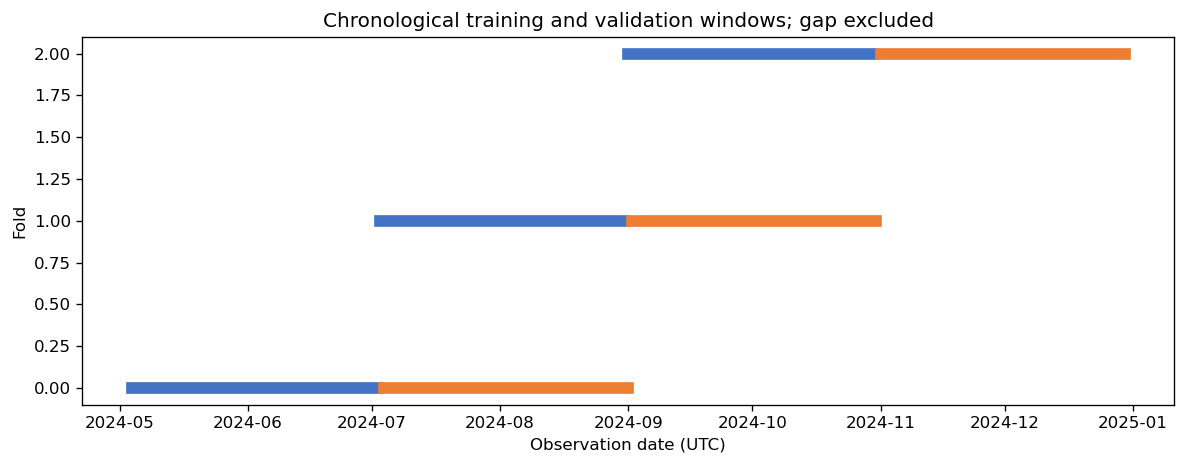

,Setting,Value
0,Target,target_2pct
1,Training start UTC,2024-05-04T00:00:00+00:00
2,Training end UTC,2024-07-02T00:00:00+00:00
3,Evaluation start UTC,2024-07-04T00:00:00+00:00
4,Evaluation end UTC,2024-09-01T00:00:00+00:00
5,Training rows,60
6,Evaluation rows,60
7,Selected features,"[""momentum_10"", ""atr_14"", ""true_range"", ""chaik..."


,training_mean_after_scaling,training_std_after_scaling
momentum_10,1.665335e-17,1.0
atr_14,7.068420e-16,1.0
true_range,-1.961394e-16,1.0
chaikin_ad,7.024011e-15,1.0


In [10]:
boundaries = review.split_boundaries(development, target=TARGET, window_size=WINDOW_SIZE)
display(boundaries)
display(presentation.figure_image(charts.plot_split_boundaries(boundaries)))
inspection = walkthrough.inspect_training(development, mode=MODE, overwrite=OVERWRITE)
display(walkthrough.inspection_table(inspection, "summary"))
display(walkthrough.inspection_table(inspection, "scaling"))

## 11. Executar o grid search

**Entrada:** dataset de desenvolvimento. **Função:** `walkthrough.grid_search` reutiliza `workflows.svm.run`. O grid já realiza o treinamento dos candidatos e calcula a validação. Para BTC, são 9 combinações × 186 candidatos × 3 folds = 5.022 ajustes.

O ranking usa F1 médio e os desempates aprovados. **Saídas:** resultados por fold, candidatos, configurações selecionadas, metadados e svm_results.xlsx. Esses scores são de validação, utilizados na escolha dos parâmetros.

**Comando equivalente**, na raiz do projeto:
```bash
python -m tcc_crypto.daily grid-search --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
```

In [11]:
display(review.candidates(development))
search = walkthrough.grid_search(development, mode=MODE, overwrite=OVERWRITE)
display(review.result_table(search, "fold_results", rows=12))
display(review.top_candidates(search))
display(review.result_table(search, "selected_configurations"))

,kernel,C,class_weight,gamma,degree,coef0
0,linear,0.1,None,NaN,NaN,NaN
1,linear,0.1,balanced,NaN,NaN,NaN
2,linear,1.0,None,NaN,NaN,NaN
3,linear,1.0,balanced,NaN,NaN,NaN
4,linear,10.0,None,NaN,NaN,NaN
...,...,...,...,...,...,...
181,poly,10.0,balanced,0.1,4.0,0.0
182,poly,10.0,None,0.1,4.0,0.5
183,poly,10.0,balanced,0.1,4.0,0.5
184,poly,10.0,None,0.1,4.0,1.0


,symbol,target,window_size,candidate_order,fold,kernel,C,gamma,degree,coef0,...,precision,recall,f1,balanced_accuracy,roc_auc,average_precision,metric_diagnostic,status,error,fit_seconds
0,BTCUSDT,target_2pct,60,0,0,linear,0.1,<NA>,<NA>,<NA>,...,0.000000,0.000000,0.000000,0.500000,0.697964,0.639417,,ok,,0.006853
1,BTCUSDT,target_2pct,60,1,0,linear,0.1,<NA>,<NA>,<NA>,...,0.511111,0.884615,0.647887,0.618778,0.721719,0.670802,,ok,,0.003463
2,BTCUSDT,target_2pct,60,2,0,linear,1.0,<NA>,<NA>,<NA>,...,0.000000,0.000000,0.000000,0.500000,0.634615,0.588143,,ok,,0.003208
3,BTCUSDT,target_2pct,60,3,0,linear,1.0,<NA>,<NA>,<NA>,...,0.488372,0.807692,0.608696,0.580317,0.722851,0.660112,,ok,,0.003325
4,BTCUSDT,target_2pct,60,4,0,linear,10.0,<NA>,<NA>,<NA>,...,0.000000,0.000000,0.000000,0.500000,0.589367,0.540293,,ok,,0.003681
5,BTCUSDT,target_2pct,60,5,0,linear,10.0,<NA>,<NA>,<NA>,...,0.488372,0.807692,0.608696,0.580317,0.722851,0.655848,,ok,,0.003785
6,BTCUSDT,target_2pct,60,6,0,rbf,0.1,scale,<NA>,<NA>,...,0.000000,0.000000,0.000000,0.500000,0.548643,0.554685,,ok,,0.003457
7,BTCUSDT,target_2pct,60,7,0,rbf,0.1,scale,<NA>,<NA>,...,0.360000,0.346154,0.352941,0.437783,0.460407,0.481833,,ok,,0.003494
8,BTCUSDT,target_2pct,60,8,0,rbf,0.1,0.01,<NA>,<NA>,...,0.000000,0.000000,0.000000,0.500000,0.521493,0.515935,,ok,,0.003359
9,BTCUSDT,target_2pct,60,9,0,rbf,0.1,0.01,<NA>,<NA>,...,0.500000,1.000000,0.666667,0.617647,0.737557,0.669538,,ok,,0.003671


,symbol,target,window_size,candidate_order,selection_rank,kernel,C,gamma,degree,coef0,...,failed_fold_count,mean_accuracy,mean_precision,mean_recall,mean_f1,mean_balanced_accuracy,mean_roc_auc,mean_average_precision,f1_standard_deviation,mean_fit_seconds
0,BTCUSDT,target_2pct,60,85,1,poly,1.0,scale,3,0.0,...,0,0.577778,0.484524,0.526650,0.483127,0.562195,0.565679,0.486984,0.126511,0.003241
1,BTCUSDT,target_2pct,60,151,2,poly,10.0,0.01,2,0.0,...,0,0.472222,0.430226,0.724638,0.462783,0.515869,0.528782,0.428889,0.149679,0.003241
2,BTCUSDT,target_2pct,60,175,3,poly,10.0,0.1,3,0.0,...,0,0.577778,0.479718,0.457530,0.439974,0.551119,0.555595,0.476161,0.129975,0.003231
186,BTCUSDT,target_2pct,75,61,1,poly,0.1,0.1,2,0.0,...,0,0.400000,0.392063,0.985507,0.560044,0.506267,0.480373,0.407365,0.035231,0.003272
187,BTCUSDT,target_2pct,75,49,2,poly,0.1,0.01,3,0.0,...,0,0.388889,0.388889,1.000000,0.559129,0.500000,0.602448,0.479466,0.035335,0.003238
188,BTCUSDT,target_2pct,75,57,3,poly,0.1,0.01,4,0.5,...,0,0.388889,0.388889,1.000000,0.559129,0.500000,0.594823,0.467617,0.035335,0.003250
372,BTCUSDT,target_2pct,90,169,1,poly,10.0,0.1,2,0.0,...,0,0.516667,0.415266,0.449408,0.416659,0.510621,0.500500,0.421103,0.012881,0.003482
373,BTCUSDT,target_2pct,90,79,2,poly,1.0,scale,2,0.0,...,0,0.477778,0.372964,0.498699,0.415495,0.488761,0.450156,0.394655,0.058238,0.003408
374,BTCUSDT,target_2pct,90,133,3,poly,10.0,scale,2,0.0,...,0,0.522222,0.409722,0.419042,0.403994,0.508323,0.521046,0.430472,0.019994,0.003386
558,BTCUSDT,target_3pct,60,27,1,poly,0.1,scale,2,0.5,...,0,0.555556,0.311014,0.573684,0.388654,0.542127,0.539047,0.326721,0.094511,0.003365


,symbol,target,window_size,candidate_order,selection_rank,kernel,C,gamma,degree,coef0,...,failed_fold_count,mean_accuracy,mean_precision,mean_recall,mean_f1,mean_balanced_accuracy,mean_roc_auc,mean_average_precision,f1_standard_deviation,mean_fit_seconds
0,BTCUSDT,target_2pct,60,85,1,poly,1.0,scale,3,0.0,...,0,0.577778,0.484524,0.526650,0.483127,0.562195,0.565679,0.486984,0.126511,0.003241
1,BTCUSDT,target_2pct,75,61,1,poly,0.1,0.1,2,0.0,...,0,0.400000,0.392063,0.985507,0.560044,0.506267,0.480373,0.407365,0.035231,0.003272
2,BTCUSDT,target_2pct,90,169,1,poly,10.0,0.1,2,0.0,...,0,0.516667,0.415266,0.449408,0.416659,0.510621,0.500500,0.421103,0.012881,0.003482
3,BTCUSDT,target_3pct,60,27,1,poly,0.1,scale,2,0.5,...,0,0.555556,0.311014,0.573684,0.388654,0.542127,0.539047,0.326721,0.094511,0.003365
4,BTCUSDT,target_3pct,75,43,1,poly,0.1,0.01,2,0.0,...,0,0.283333,0.257407,0.894737,0.390992,0.483954,0.454664,0.267752,0.080457,0.003396
5,BTCUSDT,target_3pct,90,155,1,poly,10.0,0.01,2,1.0,...,0,0.577778,0.311472,0.575439,0.398589,0.554467,0.551497,0.372465,0.164466,0.003357
6,BTCUSDT,target_4pct,60,87,1,poly,1.0,scale,3,0.5,...,0,0.672222,0.301852,0.484127,0.282065,0.603044,0.678707,0.335353,0.058118,0.003474
7,BTCUSDT,target_4pct,75,183,1,poly,10.0,0.1,4,0.5,...,0,0.644444,0.219287,0.464286,0.267977,0.575434,0.595544,0.288870,0.036485,0.003333
8,BTCUSDT,target_4pct,90,125,1,poly,1.0,0.1,3,1.0,...,0,0.655556,0.374074,0.555556,0.360234,0.605280,0.560302,0.280929,0.056238,0.003592


## 12. Treinar o SVM no teste final walk-forward

**Entradas:** datasets dos dois contextos e configurações selecionadas no grid desta execução. **Função:** `walkthrough.final_test` utiliza `workflows.final_evaluation.run`.

A cada dia, a janela avança: refazemos seleção, normalização e treinamento com dados passados, usando hiperparâmetros congelados. São avaliados SVM ajustado, SVM padrão e dois classificadores de referência. Janelas com uma classe ficam sem previsão; a comparação usa as mesmas datas válidas.

**Saídas:** previsões datadas, métricas, configurações congeladas, curvas e planilha final. A data escolhida abaixo serve para inspecionar um ajuste já executado, sem reduzir o período avaliado.

**Comando equivalente**, na raiz do projeto:
```bash
python -m tcc_crypto.daily final-test --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
```

In [12]:
final_results = walkthrough.final_test(development, mode=MODE, overwrite=OVERWRITE)
display(final_results.overview)
display(walkthrough.final_observation(development, feature_date=FEATURE_DATE, target=TARGET, window_size=WINDOW_SIZE))

,symbol,eligible_combinations,requested_combinations,final_combinations,evaluated_combination_dates,omitted_combination_dates,exclusion_reasons
0,BTCUSDT,9,9,9,5472,0,


,model,feature_date_utc,target_date_utc,training_start_utc,training_end_utc,gap_date_utc,training_rows,selected_features,scaler_mean,scaler_scale,actual,prediction,status
0,tuned_svc,2025-01-01 00:00:00+00:00,2025-01-02 00:00:00+00:00,2024-11-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,2024-12-31 00:00:00+00:00,60,momentum_10|atr_14|true_range|obv,"[4465.5448333333325, 3567.4288431400246, 3944....","[7501.172059918923, 659.9750596660529, 2199.82...",1,0,ok
1,default_svc,2025-01-01 00:00:00+00:00,2025-01-02 00:00:00+00:00,2024-11-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,2024-12-31 00:00:00+00:00,60,momentum_10|atr_14|true_range|obv,"[4465.5448333333325, 3567.4288431400246, 3944....","[7501.172059918923, 659.9750596660529, 2199.82...",1,0,ok
2,always_negative,2025-01-01 00:00:00+00:00,2025-01-02 00:00:00+00:00,2024-11-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,2024-12-31 00:00:00+00:00,60,momentum_10|atr_14|true_range|obv,"[4465.5448333333325, 3567.4288431400246, 3944....","[7501.172059918923, 659.9750596660529, 2199.82...",1,0,ok
3,training_class_frequency,2025-01-01 00:00:00+00:00,2025-01-02 00:00:00+00:00,2024-11-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,2024-12-31 00:00:00+00:00,60,momentum_10|atr_14|true_range|obv,"[4465.5448333333325, 3567.4288431400246, 3944....","[7501.172059918923, 659.9750596660529, 2199.82...",1,0,ok


## 13. Calcular o in sample dos candidatos selecionados

**Função:** `walkthrough.training_review`. Reconstruímos somente os candidatos selecionados nos três folds de desenvolvimento e verificamos a reprodução das métricas de validação antes de aceitar os scores de treinamento. Para BTC são 27 ajustes.

**Saída:** supervisor_review/training_fold_metrics.csv e metadados. O in sample é a média dos folds originais de treinamento, e não a média das janelas diárias do teste final.

**Comando equivalente**, na raiz do projeto:
```bash
python -m tcc_crypto.daily training-review --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
```

In [13]:
training_metrics = walkthrough.training_review(development, mode=MODE, overwrite=OVERWRITE)
display(training_metrics)

,symbol,target,window_size,candidate_order,fold,training_start_utc,training_end_utc,validation_start_utc,validation_end_utc,training_rows,...,selected_features,validation_reproduced,in_sample_accuracy,in_sample_precision,in_sample_recall,in_sample_f1,in_sample_balanced_accuracy,in_sample_roc_auc,in_sample_average_precision,in_sample_metric_diagnostic
0,BTCUSDT,target_2pct,60,85,0,2024-05-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,60,...,momentum_10|atr_14|true_range|chaikin_ad,True,0.716667,0.450000,0.600000,0.514286,0.677778,0.795556,0.534955,
1,BTCUSDT,target_2pct,60,85,1,2024-07-03 00:00:00+00:00,2024-08-31 00:00:00+00:00,2024-09-02 00:00:00+00:00,2024-10-31 00:00:00+00:00,60,...,momentum_10|atr_14|true_range|chaikin_ad|obv,True,0.733333,0.695652,0.640000,0.666667,0.720000,0.825143,0.747940,
2,BTCUSDT,target_2pct,60,85,2,2024-09-01 00:00:00+00:00,2024-10-30 00:00:00+00:00,2024-11-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,60,...,momentum_10|atr_14|true_range|chaikin_ad,True,0.716667,0.666667,0.454545,0.540541,0.661483,0.752392,0.715702,
3,BTCUSDT,target_2pct,75,61,0,2024-04-19 00:00:00+00:00,2024-07-02 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,75,...,momentum_10|atr_14|true_range|chaikin_ad,True,0.280000,0.270270,1.000000,0.425532,0.509091,0.670909,0.479473,
4,BTCUSDT,target_2pct,75,61,1,2024-06-18 00:00:00+00:00,2024-08-31 00:00:00+00:00,2024-09-02 00:00:00+00:00,2024-10-31 00:00:00+00:00,75,...,momentum_10|atr_14|true_range|chaikin_ad,True,0.386667,0.386667,1.000000,0.557692,0.500000,0.586957,0.506332,
5,BTCUSDT,target_2pct,75,61,2,2024-08-17 00:00:00+00:00,2024-10-30 00:00:00+00:00,2024-11-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,75,...,momentum_10|atr_14|true_range|chaikin_ad,True,0.360000,0.360000,1.000000,0.529412,0.500000,0.742284,0.576486,
6,BTCUSDT,target_2pct,90,169,0,2024-04-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,90,...,momentum_10|rsi_14|atr_14|true_range|chaikin_a...,True,0.755556,0.619048,0.481481,0.541667,0.677249,0.753674,0.660142,
7,BTCUSDT,target_2pct,90,169,1,2024-06-03 00:00:00+00:00,2024-08-31 00:00:00+00:00,2024-09-02 00:00:00+00:00,2024-10-31 00:00:00+00:00,90,...,momentum_10|atr_14|true_range|chaikin_ad|obv,True,0.700000,0.550000,0.709677,0.619718,0.702296,0.751230,0.566940,
8,BTCUSDT,target_2pct,90,169,2,2024-08-02 00:00:00+00:00,2024-10-30 00:00:00+00:00,2024-11-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,90,...,momentum_10|atr_14|true_range|chaikin_ad,True,0.677778,0.567568,0.617647,0.591549,0.665966,0.720063,0.529252,
9,BTCUSDT,target_3pct,60,27,0,2024-05-04 00:00:00+00:00,2024-07-02 00:00:00+00:00,2024-07-04 00:00:00+00:00,2024-09-01 00:00:00+00:00,60,...,momentum_10|atr_14|true_range|chaikin_ad,True,0.500000,0.256410,0.909091,0.400000,0.658627,0.810761,0.589663,


## 14. Interpretar e comparar as fases

**Entrada:** resultados salvos desta moeda e execução. **Funções:** `results_review.load_results` e os auxiliares de apresentação. As médias dos folds de treinamento/validação e as métricas das previsões finais têm protocolos de agregação diferentes.

Precisão mede acerto dos sinais positivos; recall mede quantos positivos foram encontrados; F1 combina ambos. Acurácia pode ser alta em uma classe dominante. Analise também acurácia balanceada, ROC-AUC, average precision, contagens e omissões. Nenhuma configuração é escolhida novamente pelo teste final.

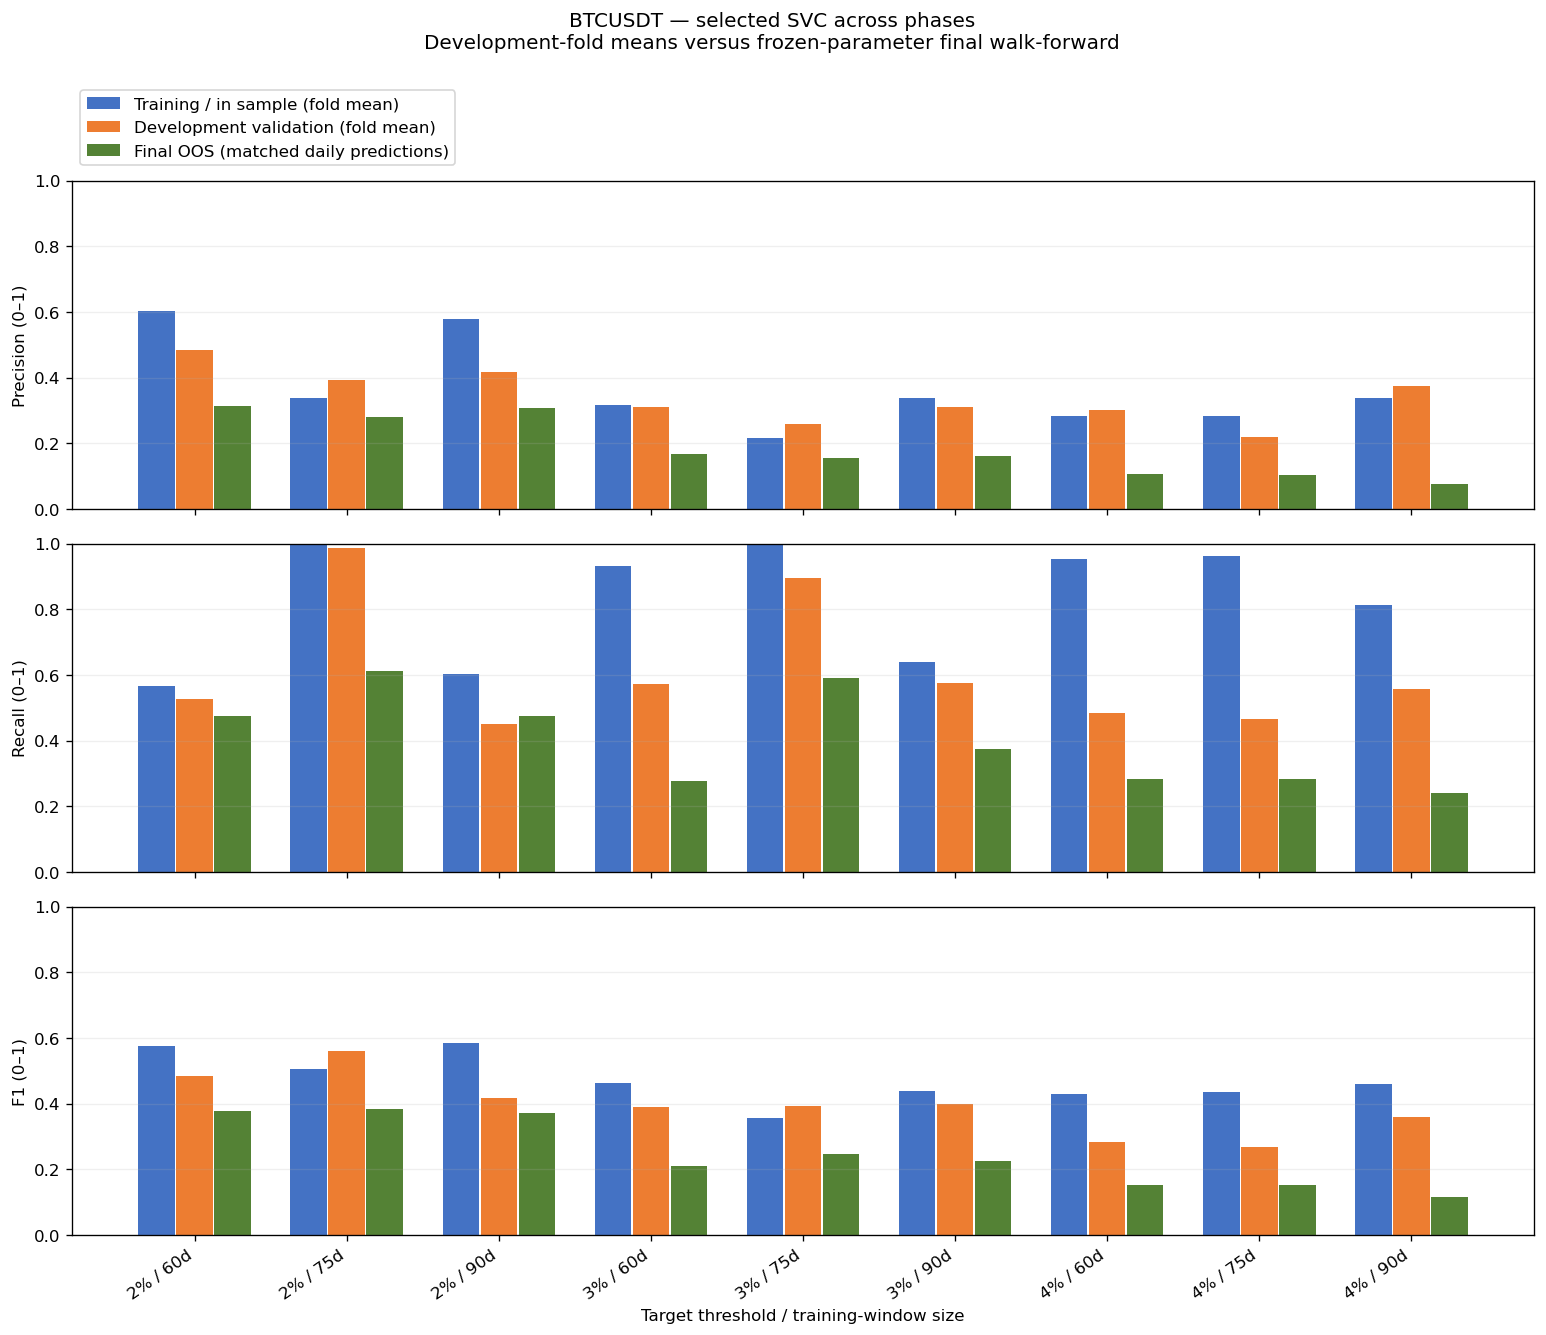

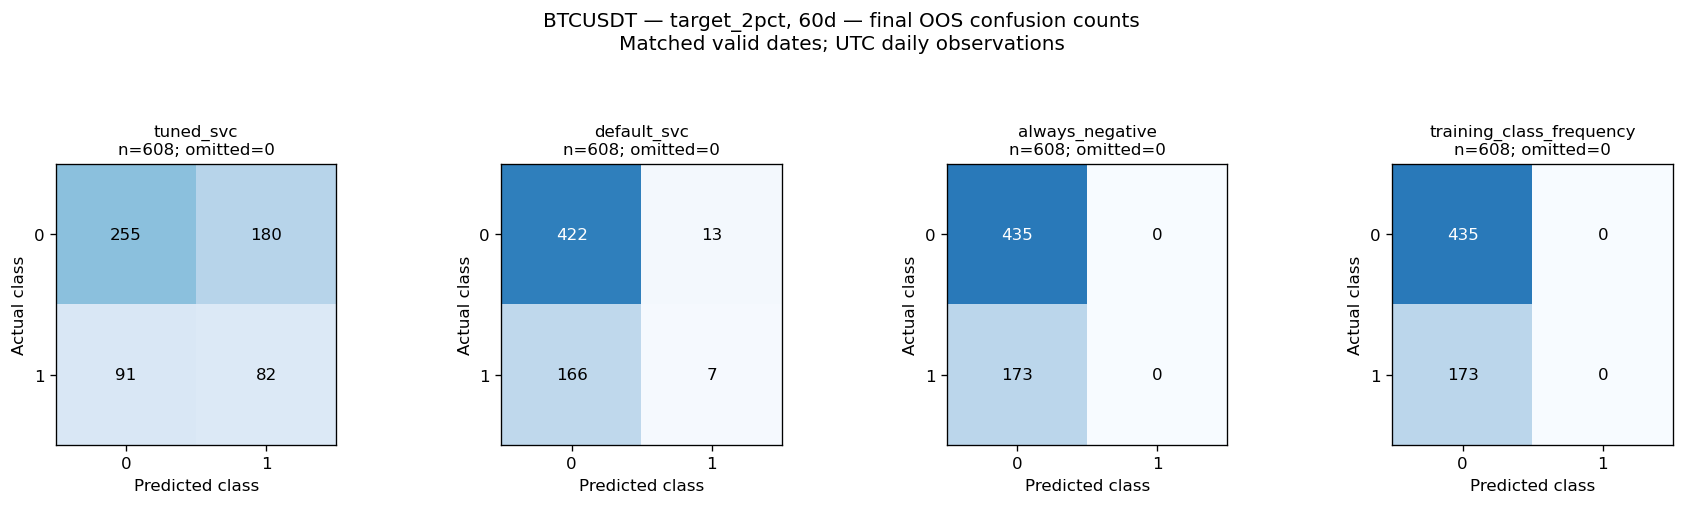

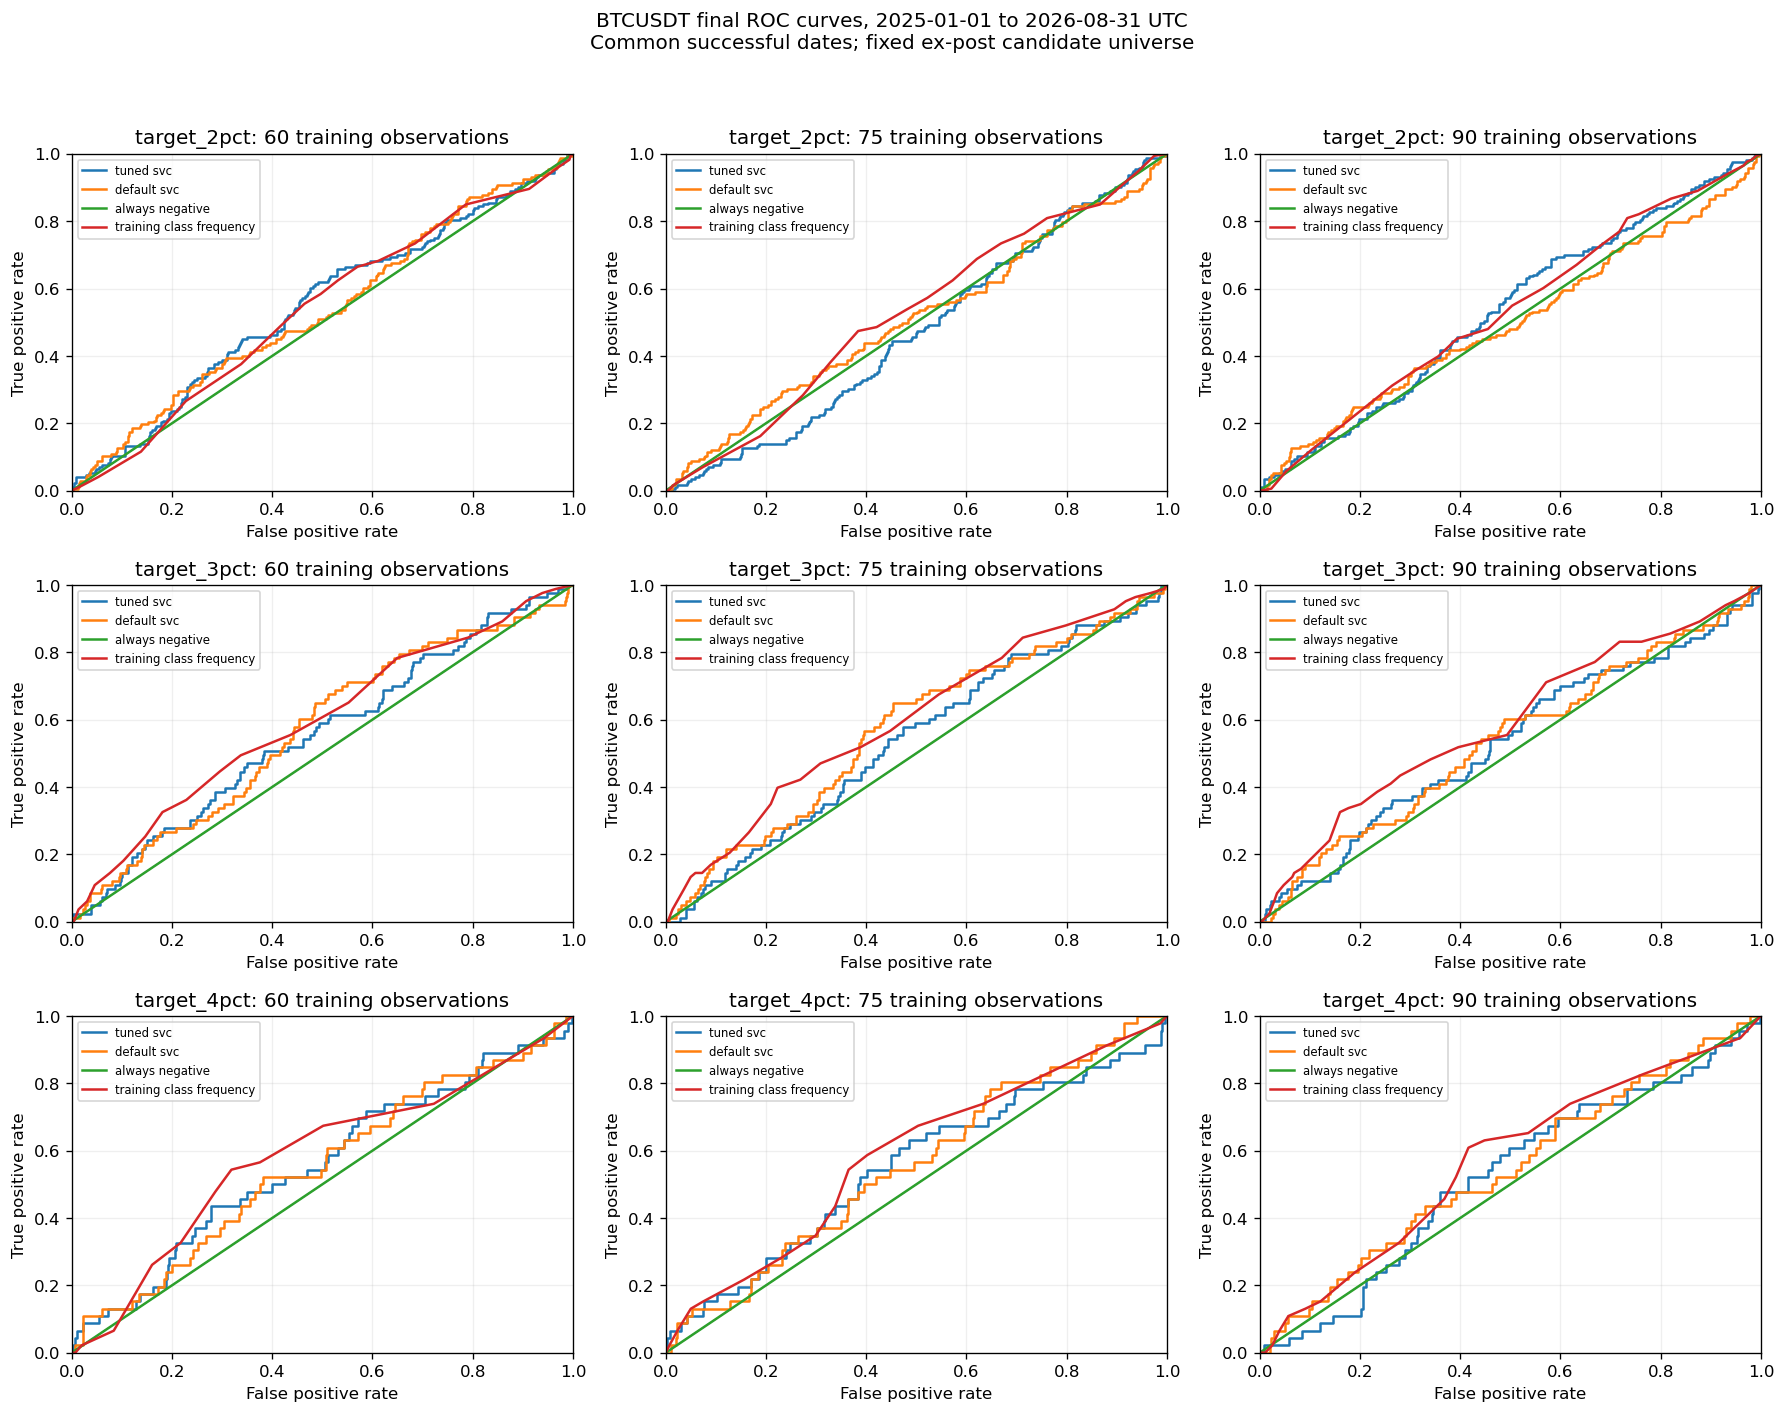

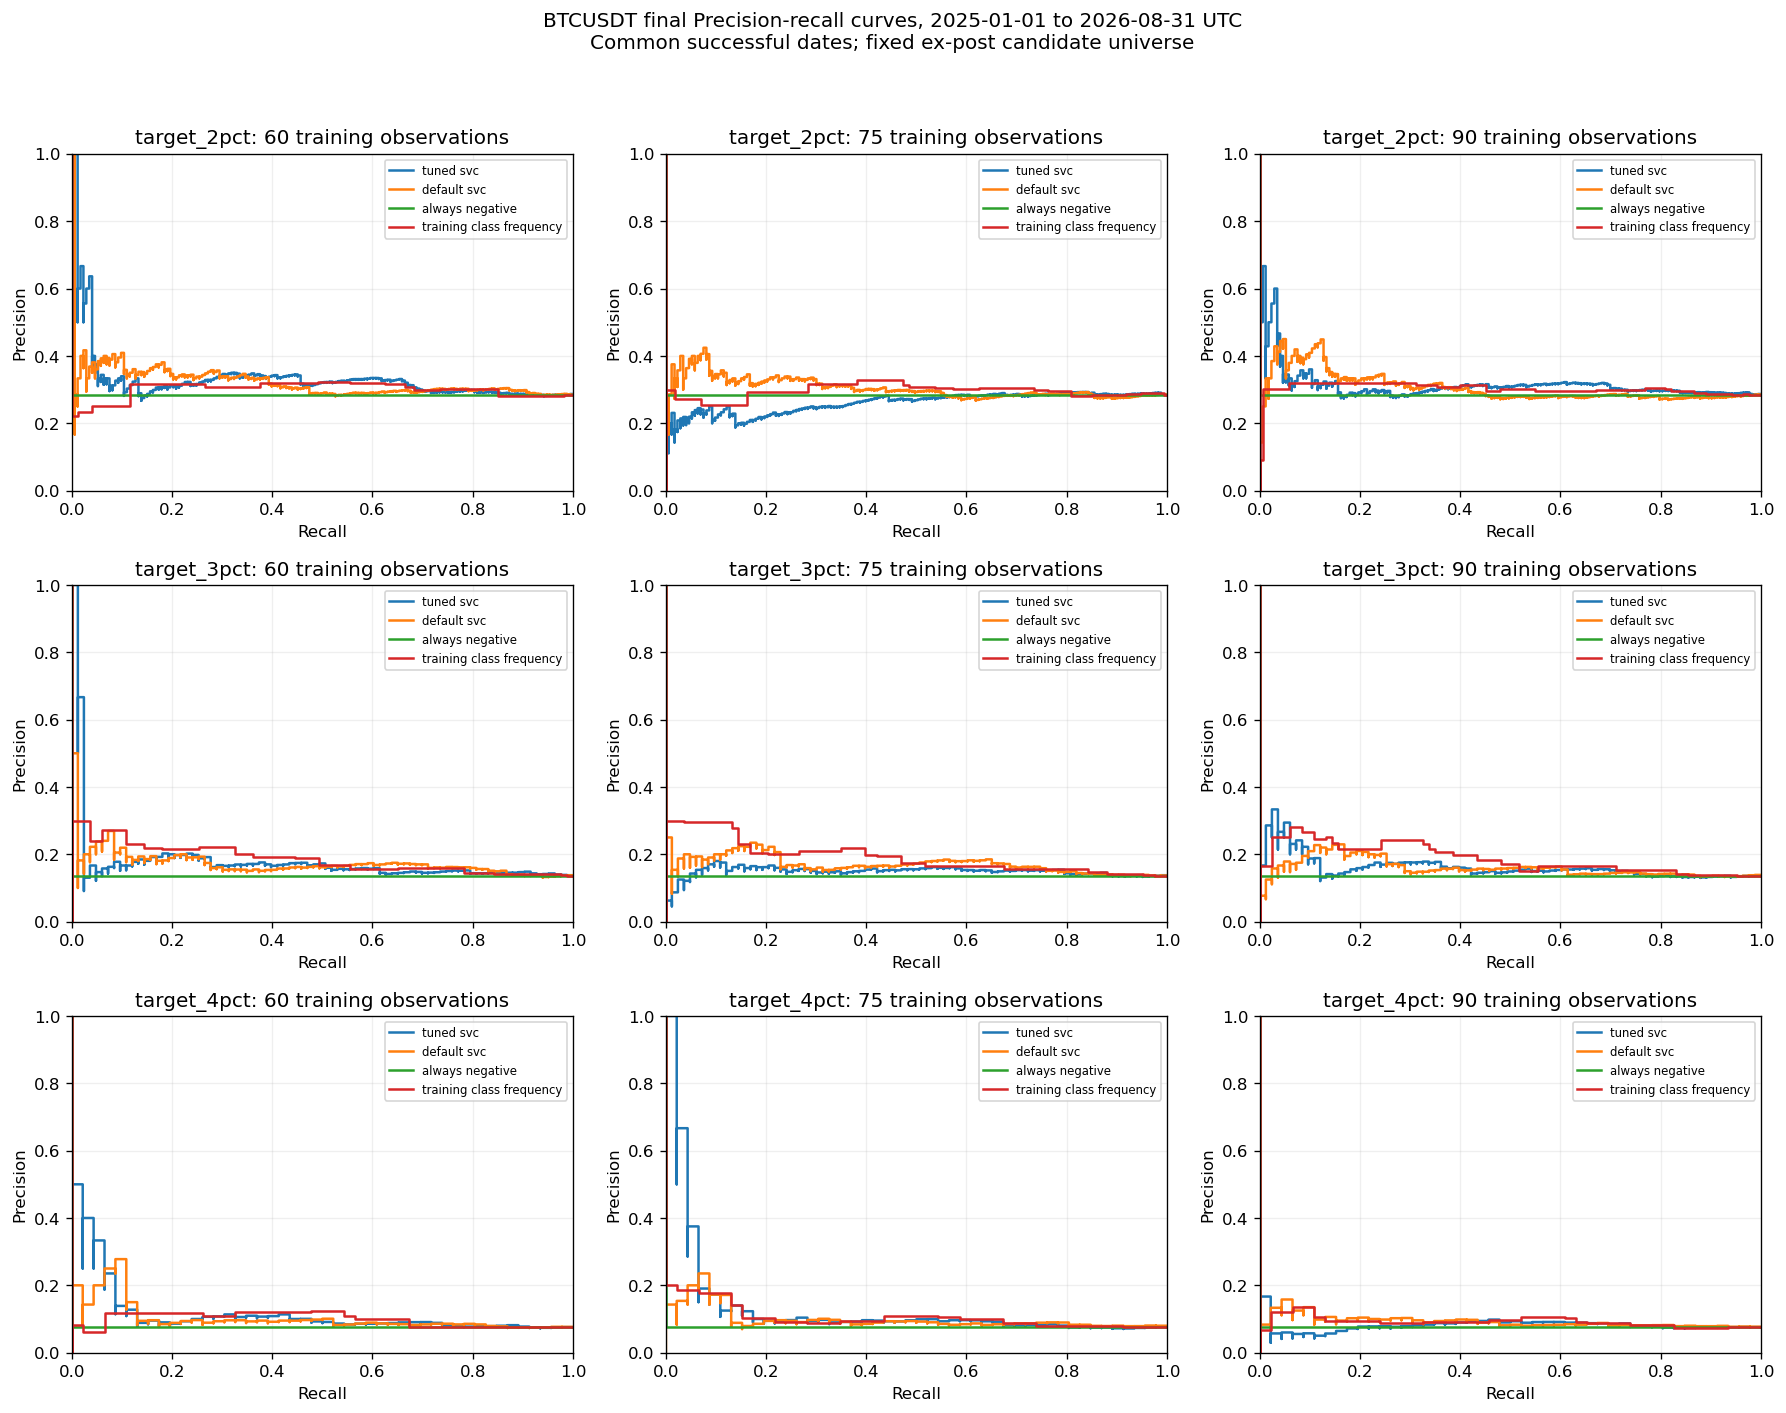

In [14]:
results = results_review.load_results(symbols=(SYMBOL,), run_id=RUN_ID)
comparison = results_review.asset_comparison(results, SYMBOL)
metrics = results_review.asset_metrics(results, SYMBOL)
curves = results_review.asset_curves(results, SYMBOL)
display(presentation.comparison_table(comparison))
display(presentation.figure_image(presentation.phase_comparison(comparison, symbol=SYMBOL)))
display(presentation.baseline_table(metrics))
display(presentation.figure_image(presentation.confusion_figure(metrics, symbol=SYMBOL, target=TARGET, window_size=WINDOW_SIZE)))
display(presentation.figure_image(presentation.curve_figure(curves, metrics, symbol=SYMBOL, kind="roc")))
display(presentation.figure_image(presentation.curve_figure(curves, metrics, symbol=SYMBOL, kind="precision_recall")))

## 15. Reabrir, exportar e executar pelo terminal

Para consultar esta execução novamente, use o mesmo `RUN_ID` e `MODE="load"`. Nenhum treinamento será repetido. A opção `EXPORT_WORKBOOKS=True` abaixo regenera explicitamente as planilhas a partir das tabelas salvas, permitindo substituir somente essas cópias de inspeção desta execução.

As opções `--run-id` e o comando `training-review` foram adicionados para este roteiro; os demais comandos já faziam parte da interface. O perfil `experiment` prepara o período completo; grid e teste final usam o perfil `development` (padrão).

**Alternativa à preparação manual das seções 5–8:** em uma nova execução, use os dois comandos `prepare` abaixo. Não execute as duas alternativas sobre os mesmos arquivos sem intenção de sobrescrita.

**Comando equivalente**, na raiz do projeto:
```bash
python -m tcc_crypto.daily prepare --profile development --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
python -m tcc_crypto.daily prepare --profile experiment --symbols BTCUSDT --run-id supervisor_20261029_btc_v1
python -m tcc_crypto.daily export --profile development --kind dataset --symbols BTCUSDT --run-id supervisor_20261029_btc_v1 --overwrite
python -m tcc_crypto.daily export --profile experiment --kind dataset --symbols BTCUSDT --run-id supervisor_20261029_btc_v1 --overwrite
python -m tcc_crypto.daily export --kind results --symbols BTCUSDT --run-id supervisor_20261029_btc_v1 --overwrite
python -m tcc_crypto.daily export --kind final-results --symbols BTCUSDT --run-id supervisor_20261029_btc_v1 --overwrite
```

In [15]:
saved_results = results_review.load_results(symbols=(SYMBOL,), run_id=RUN_ID)
display(saved_results.artifacts)
display(walkthrough.export_saved(development, regenerate=EXPORT_WORKBOOKS, overwrite=True))

,symbol,grid_workbook,final_workbook,dated_predictions,final_metrics
0,BTCUSDT,/Users/marcelapsilverio/projetos/tcc_crypto/ou...,/Users/marcelapsilverio/projetos/tcc_crypto/ou...,/Users/marcelapsilverio/projetos/tcc_crypto/ou...,/Users/marcelapsilverio/projetos/tcc_crypto/ou...


,Setting,Value
0,development.raw_directory,/Users/marcelapsilverio/projetos/tcc_crypto/da...
1,development.aligned,/Users/marcelapsilverio/projetos/tcc_crypto/da...
2,development.features,/Users/marcelapsilverio/projetos/tcc_crypto/da...
3,development.targets,/Users/marcelapsilverio/projetos/tcc_crypto/da...
4,development.dataset,/Users/marcelapsilverio/projetos/tcc_crypto/da...
5,development.dataset_workbook,/Users/marcelapsilverio/projetos/tcc_crypto/ou...
6,development.eligibility,/Users/marcelapsilverio/projetos/tcc_crypto/ou...
7,development.fold_results,/Users/marcelapsilverio/projetos/tcc_crypto/ou...
8,development.candidate_results,/Users/marcelapsilverio/projetos/tcc_crypto/ou...
9,development.selected_configurations,/Users/marcelapsilverio/projetos/tcc_crypto/ou...


### Repetir para todas as moedas

Esta sequência é opcional e mais demorada. O identificador é diferente para preservar a demonstração individual. Moedas e combinações inelegíveis permanecem documentadas. A consolidação do universo é feita ao terminar `final-test --all-symbols`.

```bash
python -m tcc_crypto.daily prepare --profile development --all-symbols --run-id supervisor_universe_001
python -m tcc_crypto.daily prepare --profile experiment --all-symbols --run-id supervisor_universe_001
python -m tcc_crypto.daily grid-search --all-symbols --run-id supervisor_universe_001
python -m tcc_crypto.daily final-test --all-symbols --run-id supervisor_universe_001
python -m tcc_crypto.daily training-review --all-symbols --run-id supervisor_universe_001
```

Os comandos não coletam novos dados brutos. A comparação financeira de carteiras, Markowitz, custos e backtest permanece fora deste roteiro.